In [99]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time
import os 
import joblib
import seaborn as sns
from sklearn.metrics import confusion_matrix   
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
import tensorflow as tf
print(tf.__version__)
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

import warnings
warnings.filterwarnings("ignore")

2.21.0


In [100]:
df = pd.read_csv("job_salary_prediction_dataset.csv")
df

,job_title,experience_years,education_level,skills_count,industry,company_size,location,remote_work,certifications,salary
0,AI Engineer,10,Bachelor,2,Healthcare,Medium,India,Hybrid,2,109413
1,Data Analyst,5,Bachelor,17,Telecom,Small,Australia,No,0,93764
2,Frontend Developer,18,PhD,4,Media,Medium,Singapore,No,1,148123
3,Business Analyst,19,PhD,13,Retail,Medium,Canada,Yes,0,189123
4,Product Manager,15,Bachelor,7,Manufacturing,Large,Sweden,Yes,0,165069
...,...,...,...,...,...,...,...,...,...,...
249995,Software Engineer,17,PhD,2,Telecom,Enterprise,India,No,1,127791
249996,Frontend Developer,20,PhD,7,Telecom,Startup,Remote,No,2,154593
249997,Business Analyst,1,Bachelor,12,Retail,Enterprise,India,Yes,0,75988
249998,Data Scientist,0,High School,2,Consulting,Small,Sweden,Hybrid,5,90467


In [101]:
print("DataFrame type:", type(df))
print("Dataset shape:", df.shape)

print("\nActual column names:")
for col in df.columns:
    print(repr(col))

DataFrame type: <class 'pandas.DataFrame'>
Dataset shape: (250000, 10)

Actual column names:
'job_title'
'experience_years'
'education_level'
'skills_count'
'industry'
'company_size'
'location'
'remote_work'
'certifications'
'salary'


In [102]:
features = [
    'job_title',
    'experience_years',
    'education_level',
    'skills_count',
    'industry',
    'company_size',
    'location',
    'remote_work',
    'certifications'
]

target = 'salary'

X = df[features]
y = df[target]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (250000, 9)
y shape: (250000,)


In [103]:
print(df.head())

            job_title  experience_years education_level  skills_count  \
0         AI Engineer                10        Bachelor             2   
1        Data Analyst                 5        Bachelor            17   
2  Frontend Developer                18             PhD             4   
3    Business Analyst                19             PhD            13   
4     Product Manager                15        Bachelor             7   

        industry company_size   location remote_work  certifications  salary  
0     Healthcare       Medium      India      Hybrid               2  109413  
1        Telecom        Small  Australia          No               0   93764  
2          Media       Medium  Singapore          No               1  148123  
3         Retail       Medium     Canada         Yes               0  189123  
4  Manufacturing        Large     Sweden         Yes               0  165069  


In [104]:
print("\nDataset shape:", df.shape)


Dataset shape: (250000, 10)


In [105]:
print("\nColumns:")
print(df.columns.tolist())


Columns:
['job_title', 'experience_years', 'education_level', 'skills_count', 'industry', 'company_size', 'location', 'remote_work', 'certifications', 'salary']


In [106]:
print("\nDataset information:")
df.info()


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 10 columns):
 #   Column            Non-Null Count   Dtype
---  ------            --------------   -----
 0   job_title         250000 non-null  str  
 1   experience_years  250000 non-null  int64
 2   education_level   250000 non-null  str  
 3   skills_count      250000 non-null  int64
 4   industry          250000 non-null  str  
 5   company_size      250000 non-null  str  
 6   location          250000 non-null  str  
 7   remote_work       250000 non-null  str  
 8   certifications    250000 non-null  int64
 9   salary            250000 non-null  int64
dtypes: int64(4), str(6)
memory usage: 30.7 MB


In [107]:
print("\nMissing values:")
print(df.isnull().sum())


Missing values:
job_title           0
experience_years    0
education_level     0
skills_count        0
industry            0
company_size        0
location            0
remote_work         0
certifications      0
salary              0
dtype: int64


In [108]:
print("\nStatistical summary:")
print(df.describe(include="all"))


Statistical summary:
                job_title  experience_years education_level   skills_count  \
count              250000     250000.000000          250000  250000.000000   
unique                 12               NaN               5            NaN   
top     Backend Developer               NaN          Master            NaN   
freq                21125               NaN           50352            NaN   
mean                  NaN         10.005408             NaN       9.997812   
std                   NaN          6.060602             NaN       5.479288   
min                   NaN          0.000000             NaN       1.000000   
25%                   NaN          5.000000             NaN       5.000000   
50%                   NaN         10.000000             NaN      10.000000   
75%                   NaN         15.000000             NaN      15.000000   
max                   NaN         20.000000             NaN      19.000000   

       industry company_size   location r

In [109]:
print("Duplicate rows:", df.duplicated().sum())

print("\nMissing values:")
display(
    df.isnull().sum().sort_values(ascending=False)
)

print("\nNumerical summary:")
display(df.describe(include="all").T)

Duplicate rows: 0

Missing values:


job_title           0
experience_years    0
education_level     0
skills_count        0
industry            0
company_size        0
location            0
remote_work         0
certifications      0
salary              0
dtype: int64


Numerical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
job_title,250000,12,Backend Developer,21125,NaN,NaN,NaN,NaN,NaN,NaN,NaN
experience_years,250000.0,NaN,NaN,NaN,10.005408,6.060602,0.0,5.0,10.0,15.0,20.0
education_level,250000,5,Master,50352,NaN,NaN,NaN,NaN,NaN,NaN,NaN
skills_count,250000.0,NaN,NaN,NaN,9.997812,5.479288,1.0,5.0,10.0,15.0,19.0
industry,250000,10,Finance,25393,NaN,NaN,NaN,NaN,NaN,NaN,NaN
company_size,250000,5,Large,50254,NaN,NaN,NaN,NaN,NaN,NaN,NaN
location,250000,10,Australia,25258,NaN,NaN,NaN,NaN,NaN,NaN,NaN
remote_work,250000,3,No,83621,NaN,NaN,NaN,NaN,NaN,NaN,NaN
certifications,250000.0,NaN,NaN,NaN,2.491928,1.706475,0.0,1.0,2.0,4.0,5.0
salary,250000.0,NaN,NaN,NaN,145718.080524,37407.952729,31867.0,119358.0,143453.0,169492.0,333046.0


In [110]:
df = df.drop_duplicates().copy()

print("Dataset shape after removing duplicates:", df.shape)

Dataset shape after removing duplicates: (250000, 10)


In [111]:
salary_candidates = [
    "salary",
    "annual_salary",
    "salary_amount",
    "predicted_salary",
    "salary_in_usd",
    "monthly_salary",
    "monthlyincome",
    "income"
]

# Map normalized column names to actual column names
normalized_columns = {
    col.lower().replace(" ", "").replace("_", ""): col
    for col in df.columns
}

target = None

for candidate in salary_candidates:
    normalized_candidate = (
        candidate.lower().replace(" ", "").replace("_", "")
    )

    if normalized_candidate in normalized_columns:
        target = normalized_columns[normalized_candidate]
        break

if target is None:
    salary_like_columns = [
        col for col in df.columns
        if "salary" in col.lower() or "income" in col.lower()
    ]

    if len(salary_like_columns) == 1:
        target = salary_like_columns[0]
    else:
        raise ValueError(
            "Could not uniquely identify the salary target.\n"
            f"Available columns: {df.columns.tolist()}\n"
            f"Possible salary columns: {salary_like_columns}\n"
            "Set target = 'YOUR_ACTUAL_SALARY_COLUMN' manually."
        )

print("Selected target column:", target)

Selected target column: salary


In [112]:
# Remove rows where the salary target is missing or nonnumeric
df[target] = pd.to_numeric(df[target], errors="coerce")

df = df[
    df[target].notna() &
    np.isfinite(df[target])
].copy()

# Exclude identifiers that normally should not be model features
identifier_columns = [
    col for col in df.columns
    if any(
        word in col.lower().replace(" ", "_")
        for word in [
            "employee_id",
            "employee_name",
            "full_name",
            "email",
            "phone_number"
        ]
    )
]

# Also exclude a plain name column
identifier_columns += [
    col for col in df.columns
    if col.lower().strip() in ["name", "id", "employeeid"]
]

identifier_columns = list(set(identifier_columns))

features = [
    col for col in df.columns
    if col != target and col not in identifier_columns
]

X = df[features].copy()
y = df[target].copy()

# Remove constant columns
constant_columns = [
    col for col in X.columns
    if X[col].nunique(dropna=False) <= 1
]

X = X.drop(columns=constant_columns)

features = X.columns.tolist()

if X.shape[1] == 0:
    raise ValueError("No usable feature columns were found.")

print("Target:", target)
print("Excluded identifier columns:", identifier_columns)
print("Excluded constant columns:", constant_columns)
print("\nFeatures used:")
print(features)

print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)

Target: salary
Excluded identifier columns: []
Excluded constant columns: []

Features used:
['job_title', 'experience_years', 'education_level', 'skills_count', 'industry', 'company_size', 'location', 'remote_work', 'certifications']

Feature shape: (250000, 9)
Target shape: (250000,)


In [113]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (200000, 9)
Testing features: (50000, 9)
Training target: (200000,)
Testing target: (50000,)


In [114]:
# Identify columns by their data types
numerical_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine the transformations
transformers = []

if numerical_features:
    transformers.append(
        ("num", numerical_transformer, numerical_features)
    )

if categorical_features:
    transformers.append(
        ("cat", categorical_transformer, categorical_features)
    )

preprocessor = ColumnTransformer(
    transformers=transformers
)

print("\nPreprocessing pipeline created successfully!")

Numerical features: ['experience_years', 'skills_count', 'certifications']
Categorical features: ['job_title', 'education_level', 'industry', 'company_size', 'location', 'remote_work']

Preprocessing pipeline created successfully!


In [115]:
# Fit on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data
X_test_processed = preprocessor.transform(X_test)

# Convert to dense arrays for TensorFlow
X_train_array = (
    X_train_processed.toarray()
    if hasattr(X_train_processed, "toarray")
    else np.asarray(X_train_processed)
)

X_test_array = (
    X_test_processed.toarray()
    if hasattr(X_test_processed, "toarray")
    else np.asarray(X_test_processed)
)

print("Processed training shape:", X_train_array.shape)
print("Processed testing shape:", X_test_array.shape)

Processed training shape: (200000, 48)
Processed testing shape: (50000, 48)


In [116]:
y_train_array = np.asarray(y_train, dtype=float).reshape(-1)
y_test_array = np.asarray(y_test, dtype=float).reshape(-1)

y_scaler = StandardScaler()

y_train_scaled = y_scaler.fit_transform(
    y_train_array.reshape(-1, 1)
).ravel()

print("Salary target scaling completed!")

Salary target scaling completed!


Build the ANN model

In [117]:
tf.keras.utils.set_random_seed(42)

ann_model = Sequential([
    Input(shape=(X_train_array.shape[1],)),

    Dense(64, activation="relu"),
    Dropout(0.2),

    Dense(32, activation="relu"),

    Dense(16, activation="relu"),

    Dense(1, activation="linear")
])

ann_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

ann_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_12 (Dense)                │ (None, 64)             │         3,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,761 (22.50 KB)

 Trainable params: 5,761 (22.50 KB)

 Non-trainable params: 0 (0.00 B)

Train the ANN

In [118]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

start_time = time.time()

ann_history = ann_model.fit(
    X_train_array,
    y_train_scaled,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=1
)

ann_training_time = time.time() - start_time

print(
    f"ANN training time: {ann_training_time:.2f} seconds"
)

Epoch 1/100
5000/5000 ━━━━━━━━━━━━━━━━━━━━ 10s 2ms/step - loss: 0.0584 - mae: 0.1710 - val_loss: 0.0272 - val_mae: 0.1309
Epoch 2/100
5000/5000 ━━━━━━━━━━━━━━━━━━━━ 11s 2ms/step - loss: 0.0238 - mae: 0.1221 - val_loss: 0.0394 - val_mae: 0.1560
Epoch 3/100
5000/5000 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step - loss: 0.0216 - mae: 0.1168 - val_loss: 0.0459 - val_mae: 0.1684
Epoch 4/100
5000/5000 ━━━━━━━━━━━━━━━━━━━━ 10s 2ms/step - loss: 0.0207 - mae: 0.1144 - val_loss: 0.0515 - val_mae: 0.1832
Epoch 5/100
5000/5000 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step - loss: 0.0203 - mae: 0.1133 - val_loss: 0.0521 - val_mae: 0.1830
Epoch 6/100
5000/5000 ━━━━━━━━━━━━━━━━━━━━ 10s 2ms/step - loss: 0.0200 - mae: 0.1126 - val_loss: 0.0564 - val_mae: 0.1920
Epoch 7/100
5000/5000 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step - loss: 0.0199 - mae: 0.1122 - val_loss: 0.0561 - val_mae: 0.1923
Epoch 8/100
5000/5000 ━━━━━━━━━━━━━━━━━━━━ 10s 2ms/step - loss: 0.0198 - mae: 0.1118 - val_loss: 0.0571 - val_mae: 0.1930
Epoch 9/100
5000/5000 ━━━━━

In [119]:
# print(ann_history.history.keys())

Visualize ANN training performance

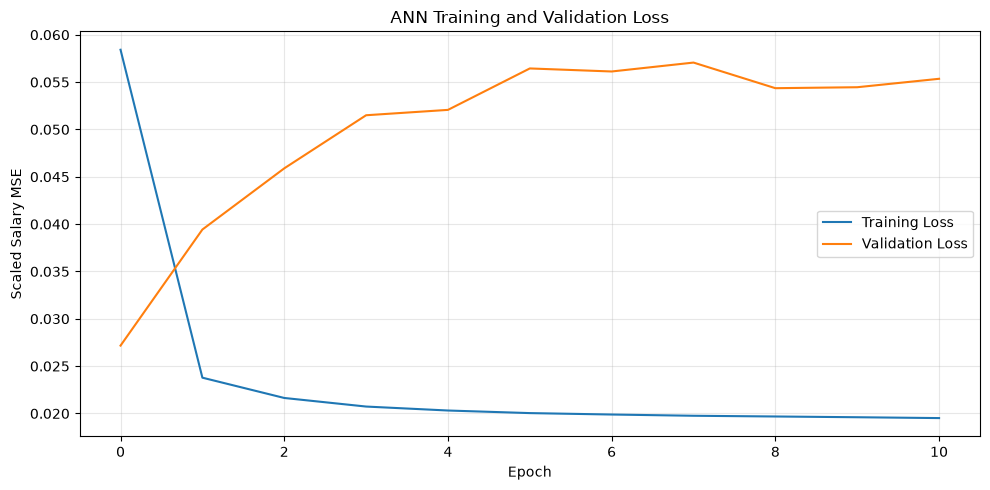

In [120]:
plt.figure(figsize=(10, 5))

plt.plot(
    ann_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    ann_history.history["val_loss"],
    label="Validation Loss"
)

plt.title("ANN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Scaled Salary MSE")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Generate ANN predictions

In [121]:
# Store model predictions and training times
predictions = {}
training_times = {}
# Generate ANN predictions
ann_predictions_scaled = ann_model.predict(
    X_test_array,
    verbose=0
)

# Convert predictions back to original salary units
ann_predictions = y_scaler.inverse_transform(
    ann_predictions_scaled
).ravel()

# Add ANN predictions to comparison dictionary
predictions["ANN"] = ann_predictions
training_times["ANN"] = ann_training_time

print("ANN predictions generated successfully!")

print("\nFirst 10 ANN predictions:")
print(np.round(ann_predictions[:10], 2))

ANN predictions generated successfully!

First 10 ANN predictions:
[169995.1   95410.58  82491.17 164955.4  117834.08 166808.39 115220.44
  81577.9  102108.83 185311.56]


Evaluate all four models

In [122]:
results = []

for name, y_pred in predictions.items():

    r2 = r2_score(y_test_array, y_pred)

    mae = mean_absolute_error(
        y_test_array,
        y_pred
    )

    mse = mean_squared_error(
        y_test_array,
        y_pred
    )

    rmse = np.sqrt(mse)

    results.append({
        "Model": name,
        "R2 Score": r2,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "Training Time (sec)": training_times[name]
    })

results_df = pd.DataFrame(results)

# Sort by R², highest first
results_df = results_df.sort_values(
    by="R2 Score",
    ascending=False
).reset_index(drop=True)

print("MODEL PERFORMANCE COMPARISON")

display(results_df.round(4))

MODEL PERFORMANCE COMPARISON


,Model,R2 Score,MAE,MSE,RMSE,Training Time (sec)
0,ANN,0.9729,4885.9961,3.761821e+07,6133.3687,105.4879


Plot the R² score comparison

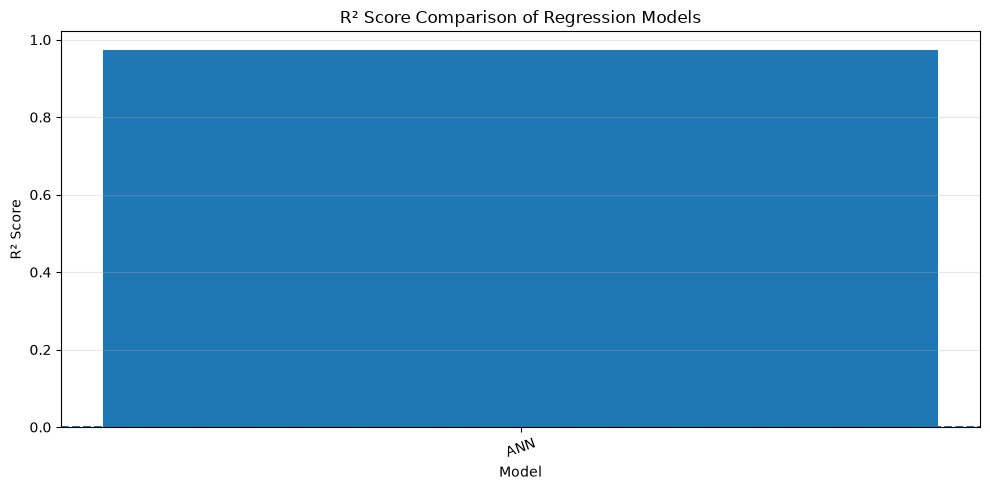

In [123]:
plt.figure(figsize=(10, 5))

plt.bar(
    results_df["Model"],
    results_df["R2 Score"]
)

plt.title("R² Score Comparison of Regression Models")
plt.xlabel("Model")
plt.ylabel("R² Score")

plt.axhline(y=0, linestyle="--")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

Compare MAE and RMSE

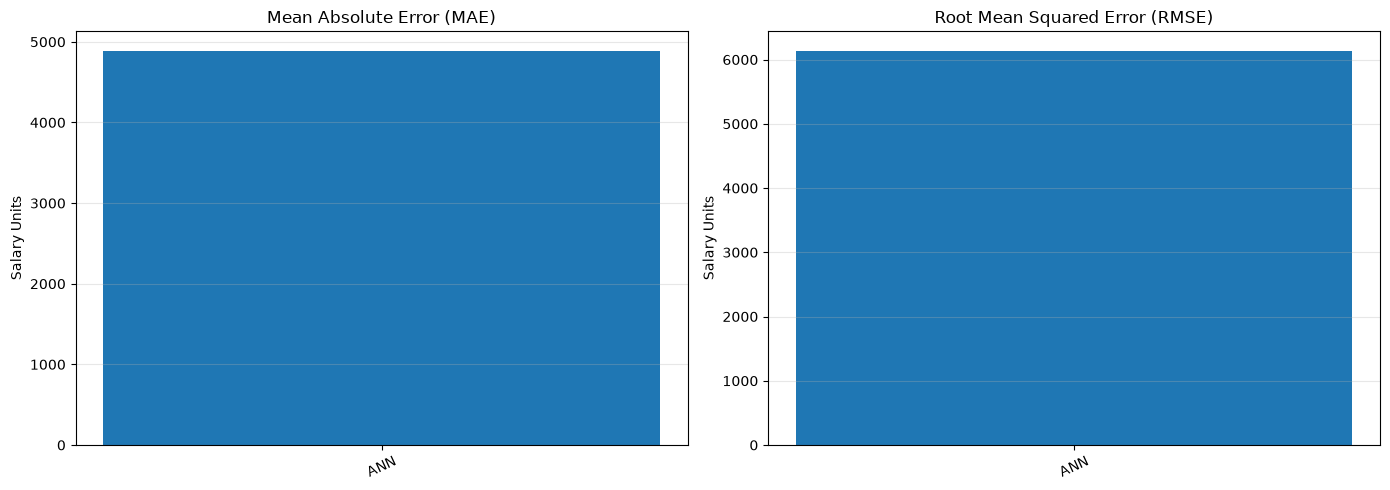

In [124]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# MAE comparison
axes[0].bar(
    results_df["Model"],
    results_df["MAE"]
)

axes[0].set_title("Mean Absolute Error (MAE)")
axes[0].set_ylabel("Salary Units")
axes[0].tick_params(axis="x", rotation=25)
axes[0].grid(axis="y", alpha=0.3)

# RMSE comparison
axes[1].bar(
    results_df["Model"],
    results_df["RMSE"]
)

axes[1].set_title("Root Mean Squared Error (RMSE)")
axes[1].set_ylabel("Salary Units")
axes[1].tick_params(axis="x", rotation=25)
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

Plot actual versus predicted salaries

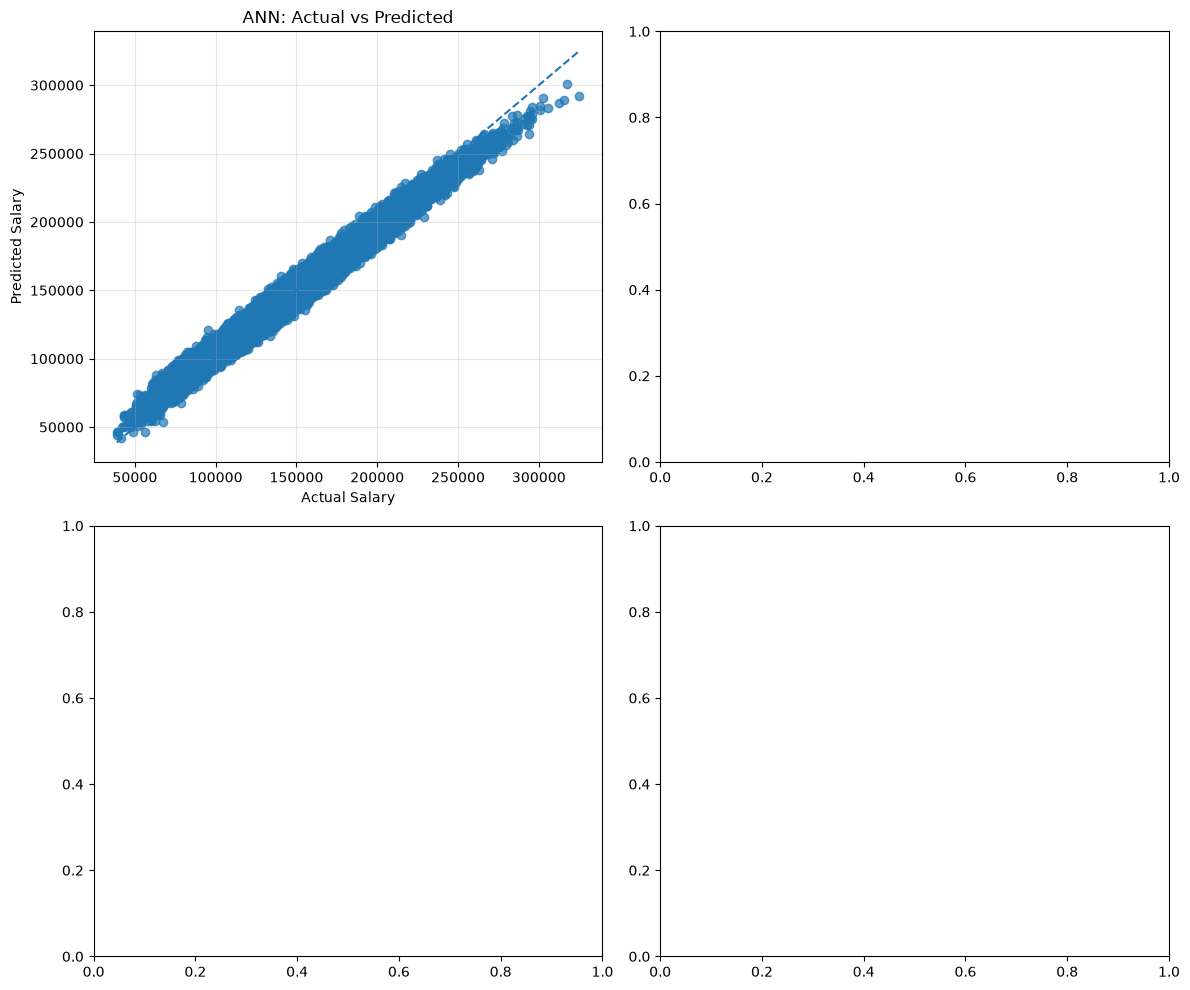

In [125]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (name, y_pred) in zip(
    axes.flatten(),
    predictions.items()
):

    ax.scatter(
        y_test_array,
        y_pred,
        alpha=0.7
    )

    min_value = min(
        y_test_array.min(),
        y_pred.min()
    )

    max_value = max(
        y_test_array.max(),
        y_pred.max()
    )

    ax.plot(
        [min_value, max_value],
        [min_value, max_value],
        linestyle="--"
    )

    ax.set_title(f"{name}: Actual vs Predicted")
    ax.set_xlabel("Actual Salary")
    ax.set_ylabel("Predicted Salary")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Identify the best-performing model

In [126]:
best_model_name = results_df.iloc[0]["Model"]

print("Best model based on test R²:", best_model_name)

print("\nPerformance of the selected model:")

display(
    results_df[
        results_df["Model"] == best_model_name
    ].round(4)
)

Best model based on test R²: ANN

Performance of the selected model:


,Model,R2 Score,MAE,MSE,RMSE,Training Time (sec)
0,ANN,0.9729,4885.9961,3.761821e+07,6133.3687,105.4879


save the trained models and results

In [127]:
# Save ANN model
ann_model.save("models/salary_ann.keras")

# Save preprocessing pipeline
joblib.dump(preprocessor, "models/salary_preprocessor.joblib")

# Save salary scaler
joblib.dump(y_scaler, "models/salary_scaler.joblib")

# Save configuration
joblib.dump({
    "features": features,
    "target": target
}, "models/salary_config.joblib")

# Save comparison results
results_df.to_csv("models/model_comparison.csv", index=False)

print("ANN model and supporting files saved successfully!")

ANN model and supporting files saved successfully!


Save the trained ANN model

In [128]:
# Save the trained ANN model in H5 format
ann_model.save("model.h5")

print("Model saved successfully as model.h5")

Model saved successfully as model.h5
